In [1]:
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

In [2]:
(X_train,y_train),(X_test,y_test)=keras.datasets.cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2327s 14us/step


In [3]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)

class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

X_train shape: (50000, 32, 32, 3)
y_train shape: (50000, 1)
X_test shape: (10000, 32, 32, 3)


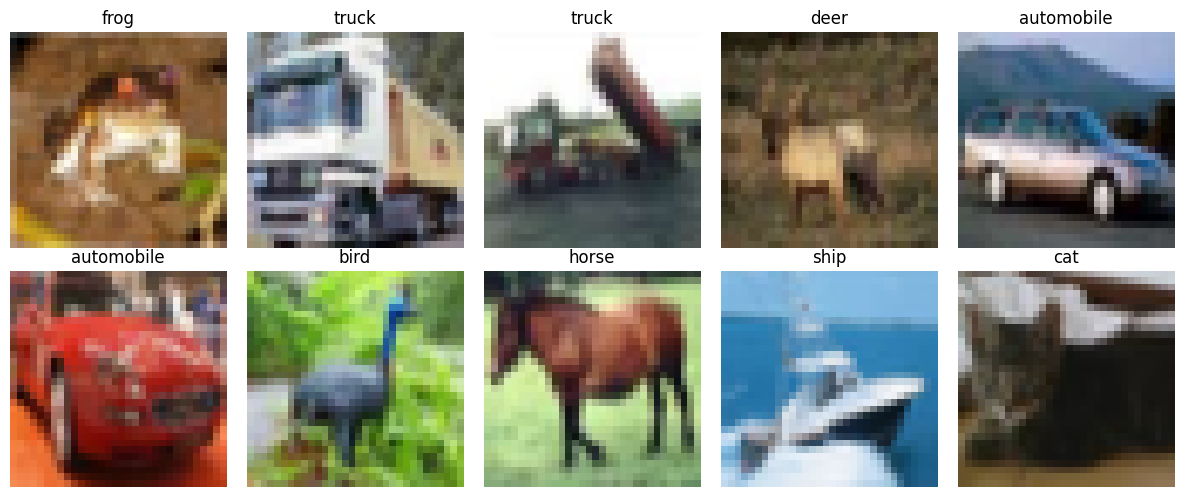

In [4]:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i])                # colour image, cmap ki zaroorat nahi
    plt.title(class_names[y_train[i][0]])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [5]:
#Normalize Images
X_train=X_train/255.0
X_test=X_test/255.0
print(X_train.max())

1.0


In [6]:
model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])


In [7]:
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])

In [8]:
history=model.fit(X_train,y_train,validation_split=0.1,epochs=15,batch_size=64)

Epoch 1/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 68s 94ms/step - accuracy: 0.3660 - loss: 1.7252 - val_accuracy: 0.4886 - val_loss: 1.4053
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 68s 97ms/step - accuracy: 0.5095 - loss: 1.3636 - val_accuracy: 0.5682 - val_loss: 1.1992
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 66s 94ms/step - accuracy: 0.5698 - loss: 1.2088 - val_accuracy: 0.6098 - val_loss: 1.0967
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 63s 90ms/step - accuracy: 0.6117 - loss: 1.1087 - val_accuracy: 0.6614 - val_loss: 0.9901
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 64s 91ms/step - accuracy: 0.6411 - loss: 1.0246 - val_accuracy: 0.6678 - val_loss: 0.9567
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 84s 94ms/step - accuracy: 0.6660 - loss: 0.9533 - val_accuracy: 0.6770 - val_loss: 0.9305
Epoch 7/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 66s 94ms/step - accuracy: 0.6877 - loss: 0.8934 - val_accuracy: 0.6840 - val_loss: 0.8949
Epoch 8/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 81s 93ms/step - accuracy: 0.7051 - loss: 0.8428 - 

In [9]:
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print("Test accuracy:", round(acc, 3))

Test accuracy: 0.723


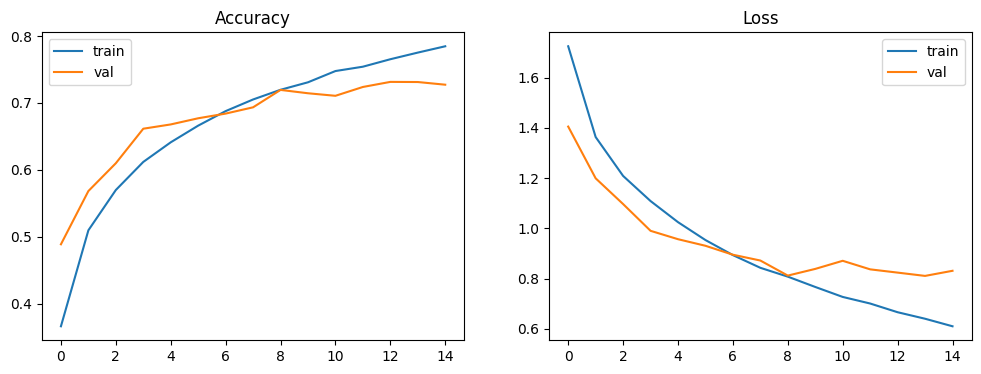

In [10]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.title("Accuracy"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.title("Loss"); plt.legend()
plt.show()

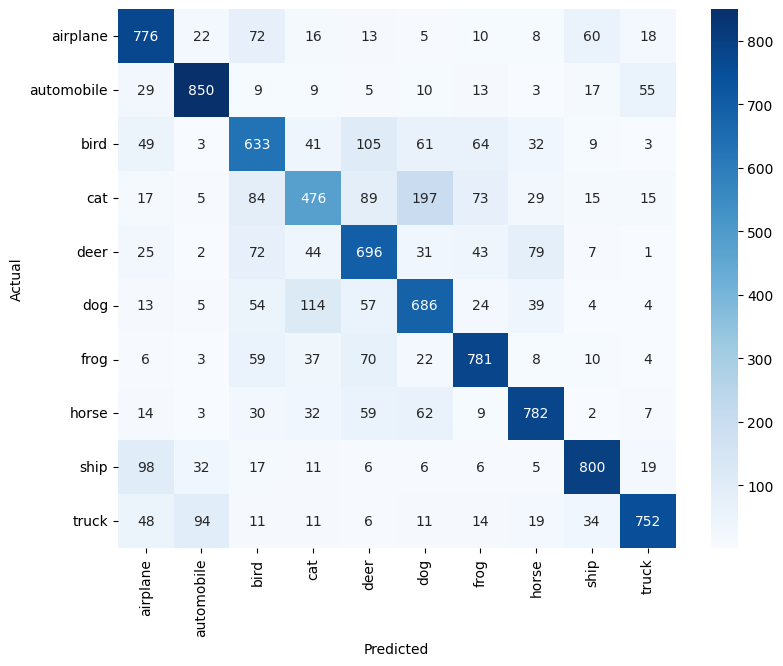

In [11]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
cm = confusion_matrix(y_test.flatten(), y_pred)   # flatten zaroori hai

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()

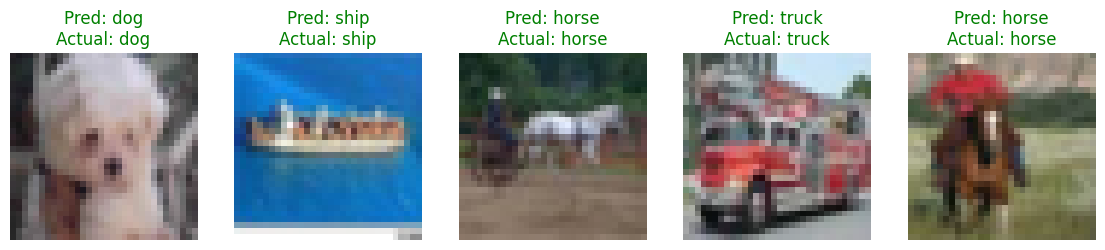

In [12]:
idx = np.random.choice(len(X_test), 5, replace=False)
plt.figure(figsize=(14, 3))
for k, i in enumerate(idx):
    pred = y_pred[i]
    actual = y_test[i][0]
    plt.subplot(1, 5, k + 1)
    plt.imshow(X_test[i])
    color = "green" if pred == actual else "red"
    plt.title(f"Pred: {class_names[pred]}\nActual: {class_names[actual]}", color=color)
    plt.axis("off")
plt.show()